# 19.5 Практическая работа

## Кластерный анализ клиентов страховой компании

Цель работы - выявить основные группы клиентов на основе характеристик страховых договоров и оценить различия между кластерами, в том числе с точки зрения убыточности.

В работе будут использованы:

- иерархическая кластеризация;
- K-Means;
- метод локтя;
- silhouette score;
- масштабирование числовых признаков;
- кодирование категориальных признаков;
- визуализация и интерпретация кластеров.

## 1. Загрузка и первичная проверка данных

Для анализа используем очищенную витрину, полученную в практической работе предыдущего модуля «Повышение качества данных».

На предыдущем этапе были:
- обработаны пропущенные значения;
- проверены дубликаты;
- удалён технический столбец;
- сформирован бинарный признак `anomaly`. В текущем анализе признак `anomaly` используется только как дополнительная характеристика данных и не участвует в построении кластеров.

Проверим структуру итоговой витрины перед началом кластерного анализа.

In [1]:
import pandas as pd
import numpy as np

df = pd.read_excel("cleaned_insurance_data.xlsx")

print("Размер таблицы:", df.shape)

print("\nТипы данных:")
print(df.dtypes)

print("\nКоличество пропусков:")
print(df.isna().sum())

print("\nКоличество полных дупликатов:")
print(df.duplicated().sum())

print("\nРаспределение anomaly:")
print(df["anomaly"].value_counts())

display(df.head())

Размер таблицы: (3711, 17)

Типы данных:
contract_num             object
product_name             object
client_id                 int64
contract_status          object
currency_name            object
duration                  int64
country                  object
age                       int64
sex                      object
price                     int64
insurance_amount          int64
loss_payout_amt           int64
price_usd               float64
insurance_amount_usd    float64
loss_payout_amt_usd     float64
premium_rate_per_day    float64
anomaly                   int64
dtype: object

Количество пропусков:
contract_num            0
product_name            0
client_id               0
contract_status         0
currency_name           0
duration                0
country                 0
age                     0
sex                     0
price                   0
insurance_amount        0
loss_payout_amt         0
price_usd               0
insurance_amount_usd    0
loss_payout_am

,contract_num,product_name,client_id,contract_status,currency_name,duration,country,age,sex,price,insurance_amount,loss_payout_amt,price_usd,insurance_amount_usd,loss_payout_amt_usd,premium_rate_per_day,anomaly
0,ТТЕ7227715*****,Страхование путешественников,10161870404,Действует,Российский рубль,10,Беларусь,20,M,1096,2000000,0,12.41768,22660.000080,0.0,0.000055,0
1,ТТЕ7227715*****,Страхование путешественников,1017159879,Действует,Российский рубль,7,Индонезия,55,M,1918,5000000,0,21.73094,56650.000199,0.0,0.000055,0
2,БАДАМСТЕ55*****,Страхование путешественников,10161883357,Действует,Российский рубль,10,Беларусь,61,F,1096,2000000,0,12.41768,22660.000080,0.0,0.000055,0
3,ТТЕ7227715*****,Страхование путешественников,100766461,Действует,Российский рубль,14,Грузия,25,M,1534,2000000,0,17.38022,22660.000080,0.0,0.000055,0
4,ТТЕ7227715*****,Страхование путешественников,10171604758,Действует,Российский рубль,7,Аргентина,33,M,1918,5000000,0,21.73094,56650.000199,0.0,0.000055,0


## 2. Проверка состава данных

Так как задача посвящена анализу действующих страховых полисов, проверим распределение статусов договоров и количество уникальных клиентов.

Это позволит понять уровень детализации данных перед построением кластеров.

In [2]:
print("Статусы договоров:")
print(df["contract_status"].value_counts())

print("\nКоличество строк:", len(df))
print("Количество уникальных договоров:", df["contract_num"].nunique())
print("Количество уникальных клиентов:", df["client_id"].nunique())

Статусы договоров:
contract_status
Действует    3315
Завершен      396
Name: count, dtype: int64

Количество строк: 3711
Количество уникальных договоров: 79
Количество уникальных клиентов: 3711


In [3]:
numeric_features = [
    "age",
    "duration",
    "price_usd",
    "insurance_amount_usd"
]

## 3. Формирование выборки для кластеризации

Так как задача посвящена анализу действующих страховых полисов, оставим только записи со статусом `Действует`.

Каждая строка соответствует уникальному клиенту, поэтому дополнительная агрегация по `client_id` не требуется.

Поле `contract_num` не используем для кластеризации, так как оно является техническим идентификатором и в обезличенной витрине повторяется.

In [4]:
df_active = df[
    df["contract_status"] == "Действует"
].copy()

print("Размер выборки действующих полисов:", df_active.shape)
print("Уникальных клиентов:", df_active["client_id"].nunique())

Размер выборки действующих полисов: (3315, 17)
Уникальных клиентов: 3315


## 4. Подготовка числовых признаков

Для первой модели кластеризации используем только числовые характеристики клиента и договора:

- `age` - возраст клиента;
- `duration` - длительность действия полиса;
- `price_usd` - стоимость полиса в долларах США;
- `insurance_amount_usd` - страховая сумма в долларах США.

Сумму страховой выплаты пока не используем при построении кластеров. Позже сравним её между полученными группами, чтобы оценить влияние характеристик кластеров на убыточность.

In [5]:
numeric_features = [
    "age",
    "duration",
    "price_usd",
    "insurance_amount_usd"
]

X_numeric = df_active[numeric_features].copy()

display(X_numeric.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,3315.0,39.892308,10.789596,20.00000,32.00000,39.000000,45.000000,89.0
duration,3315.0,25.789140,63.367936,7.00000,10.00000,14.000000,15.000000,365.0
price_usd,3315.0,59.142684,152.214398,12.41768,17.38022,26.070330,43.461880,2000.0
insurance_amount_usd,3315.0,42377.511451,17778.078899,22660.00008,22660.00008,33990.000119,56650.000199,100000.0


## 5. Масштабирование числовых признаков

Признаки имеют разные единицы измерения и масштабы.

Например, возраст измеряется десятками лет, а страховая сумма - десятками тысяч долларов. Без масштабирования признаки с большими числовыми значениями будут сильнее влиять на расстояния между объектами.

Поэтому перед кластеризацией стандартизируем данные с помощью `StandardScaler`.

In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_numeric)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=numeric_features,
    index=X_numeric.index
)

display(X_scaled.head())

print("\nСредние после масштабирования:")
print(X_scaled.mean().round(3))

print("\nСтандартные отклонения:")
print(X_scaled.std().round(3))

,age,duration,price_usd,insurance_amount_usd
0,-1.843935,-0.249204,-0.307015,-1.109259
1,1.400421,-0.296553,-0.245820,0.802935
2,1.956596,-0.249204,-0.307015,-1.109259
3,-1.380455,-0.186071,-0.274407,-1.109259
4,-0.638888,-0.296553,-0.245820,0.802935



Средние после масштабирования:
age                     0.0
duration               -0.0
price_usd               0.0
insurance_amount_usd    0.0
dtype: float64

Стандартные отклонения:
age                     1.0
duration                1.0
price_usd               1.0
insurance_amount_usd    1.0
dtype: float64


## 6. Формирование выборки для кластеризации

Для кластеризации используем все действующие страховые полисы.

Признак `anomaly`, рассчитанный в предыдущем модуле, не включаем в набор признаков модели, так как он является результатом отдельного алгоритма поиска аномалий, а не характеристикой клиента.

Аномальные записи при этом сохраняем в выборке, поскольку статистически необычная запись не обязательно является ошибочной.

In [7]:
df_model = df_active.copy()

print("Действующих полисов всего:", len(df_active))
print("Записей для кластеризации:", len(df_model))
print("Аномальные записи сохранены в выборке.")

Действующих полисов всего: 3315
Записей для кластеризации: 3315
Аномальные записи сохранены в выборке.


In [8]:
numeric_features = [
    "age",
    "duration",
    "price_usd",
    "insurance_amount_usd"
]

X_numeric = df_model[numeric_features].copy()

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_numeric)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=numeric_features,
    index=X_numeric.index
)

print("Размер данных для кластеризации:", X_scaled.shape)

Размер данных для кластеризации: (3315, 4)


## 7. Иерархическая кластеризация

Сначала применим иерархическую агломеративную кластеризацию.

Для визуальной оценки структуры данных построим дендрограмму. Она показывает последовательность объединения наблюдений и помогает оценить возможное количество кластеров.

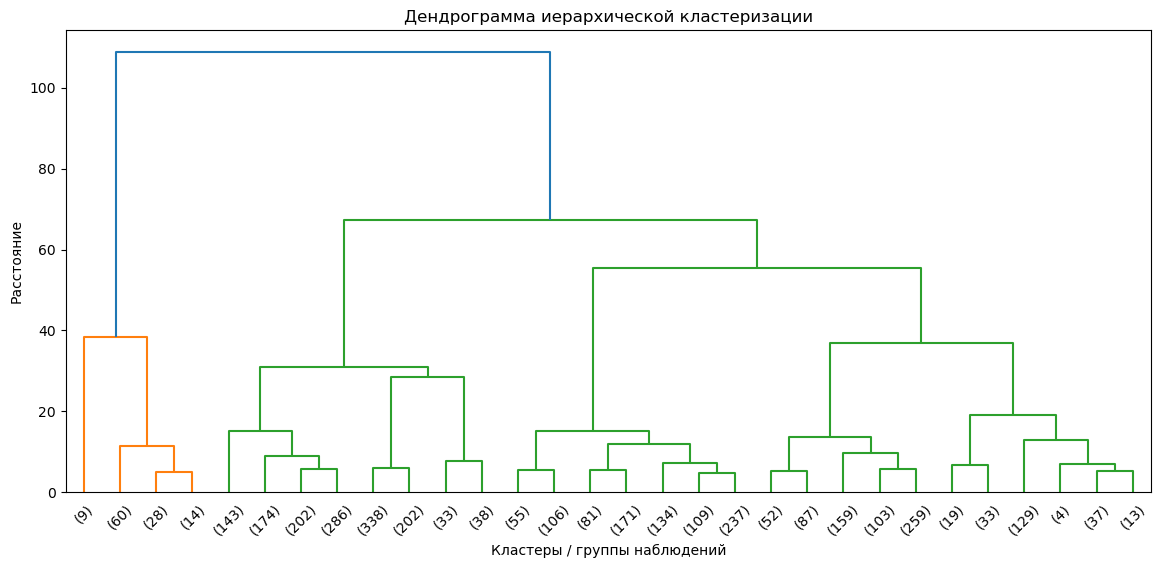

In [9]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(
    X_scaled,
    method="ward"
)

plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True
)

plt.title("Дендрограмма иерархической кластеризации")
plt.xlabel("Кластеры / группы наблюдений")
plt.ylabel("Расстояние")

plt.show()

## 8. Подбор числа кластеров для иерархической модели

По дендрограмме визуально можно предположить наличие нескольких крупных групп.

Чтобы выбрать количество кластеров более объективно, рассчитаем `silhouette_score` для нескольких вариантов.

Silhouette score показывает, насколько объект:
- похож на объекты собственного кластера;
- отличается от объектов других кластеров.

Чем выше значение, тем лучше разделены кластеры.

In [10]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

hierarchical_scores = []

for k in range(2, 9):
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    hierarchical_scores.append(score)

    print(
        f"k= {k}: "
        f"silhoutte_score = {score:.4f}"
    )

k= 2: silhoutte_score = 0.7742
k= 3: silhoutte_score = 0.4196
k= 4: silhoutte_score = 0.4491
k= 5: silhoutte_score = 0.4535
k= 6: silhoutte_score = 0.4896
k= 7: silhoutte_score = 0.4910
k= 8: silhoutte_score = 0.5094


## 9. Silhouette score для иерархической кластеризации

Построим график зависимости качества кластеризации от количества кластеров.

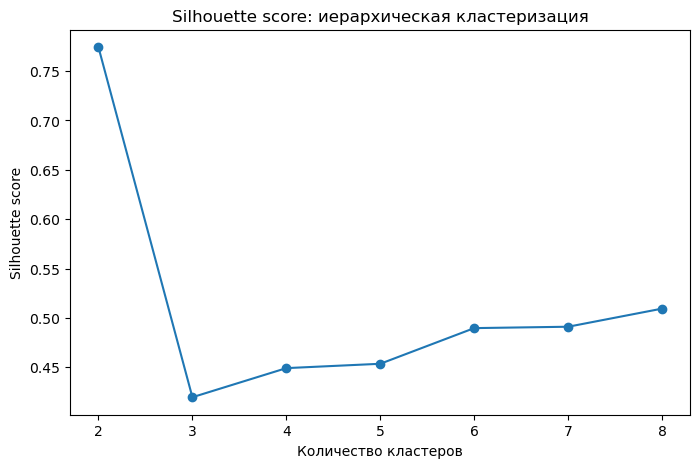

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 9),
    hierarchical_scores,
    marker="o"
)

plt.title(
    "Silhouette score: иерархическая кластеризация"
)
plt.xlabel("Количество кластеров")
plt.ylabel("Silhouette score")

plt.show()

### Вывод

Наибольшее значение `silhouette_score` получено при количестве кластеров `k = 2`:

`silhouette_score = 0.7742`.

Это значение заметно выше результатов для остальных рассмотренных вариантов количества кластеров.

Таким образом, с точки зрения метрики качества иерархическая кластеризация наиболее чётко разделяет данные на две крупные группы.

При этом для более детальной бизнес-интерпретации далее дополнительно рассмотрим разбиение на три кластера.

## 10. Подбор количества кластеров для K-Means

Для метода K-Means сначала оценим оптимальное количество кластеров с помощью метода локтя.

Для каждого значения `k` рассчитаем `inertia` - сумму квадратов расстояний объектов до центров своих кластеров.

При увеличении количества кластеров inertia уменьшается. Ищем точку, после которой уменьшение становится менее выраженным - так называемый «локоть».

In [12]:
from sklearn.cluster import KMeans

inertias = []

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertias.append(kmeans.inertia_)

    print(
        f"k = {k}: "
        f"inertia = {kmeans.inertia_:.2f}"
    )

k = 2: inertia = 7339.09
k = 3: inertia = 4684.87
k = 4: inertia = 3429.60
k = 5: inertia = 2678.59
k = 6: inertia = 2050.98
k = 7: inertia = 1492.75
k = 8: inertia = 1108.98


## 11. Метод локтя для K-Means

Визуализируем зависимость inertia от количества кластеров.

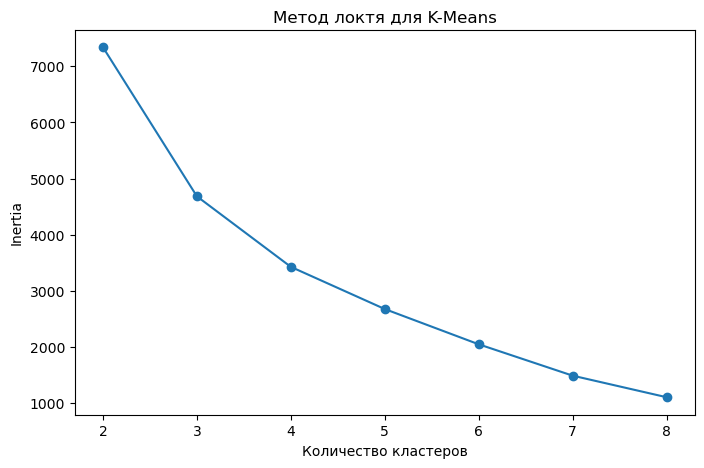

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 9),
    inertias,
    marker="o"
)

plt.title("Метод локтя для K-Means")
plt.xlabel("Количество кластеров")
plt.ylabel("Inertia")

plt.show()

## 12. Silhouette score для K-Means

Дополнительно оценим качество кластеризации с помощью `silhouette_score`.

Это позволит сравнить варианты K-Means между собой и затем сопоставить лучший результат с иерархической кластеризацией.

In [14]:
kmeans_scores = []

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    kmeans_scores.append(score)

    print(
        f"k = {k}: "
        f"silhouette_score = {score:.4f}"
    )

k = 2: silhouette_score = 0.7742
k = 3: silhouette_score = 0.4640
k = 4: silhouette_score = 0.4704
k = 5: silhouette_score = 0.4941
k = 6: silhouette_score = 0.4777
k = 7: silhouette_score = 0.5162
k = 8: silhouette_score = 0.5444


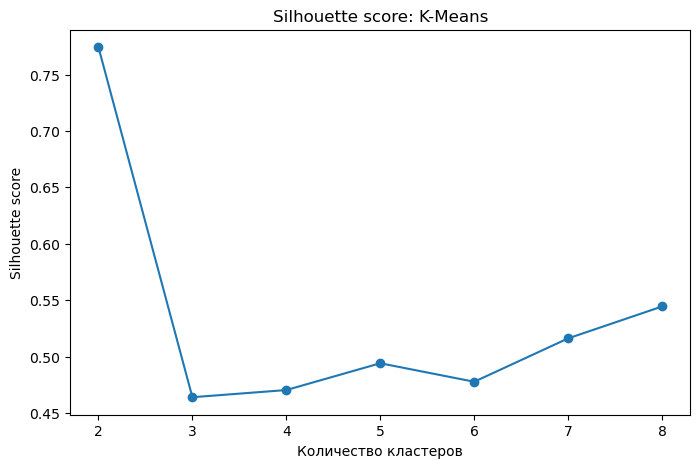

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 9),
    kmeans_scores,
    marker="o"
)

plt.title("Silhouette score: K-Means")
plt.xlabel("Количество кластеров")
plt.ylabel("Silhouette score")

plt.show()

## 13. Сравнение методов и выбор итоговой модели

По результатам анализа:

- иерархическая кластеризация показала лучший `silhouette_score = 0.7742` при `k = 2`;
- K-Means также показал `silhouette_score = 0.7742` при `k = 2`;
- для K-Means при `k = 3` значение составляет `0.4640`;
- при увеличении количества кластеров до `k = 8` значение `silhouette_score` составляет `0.5444`, но остаётся ниже результата при `k = 2`.

По чистой метрике качества наиболее сильное разделение получается при двух кластерах.

Для дальнейшей бизнес-интерпретации используем K-Means с тремя кластерами.

Такое разбиение позволяет выделить отдельную небольшую группу клиентов с очень длительными и дорогими полисами, которая при более грубом разбиении может объединяться с другими наблюдениями.

Поэтому `k = 3` выбирается не как математически лучший вариант по silhouette, а как более детальное и содержательное разбиение для бизнес-анализа.

In [16]:
final_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df_model["cluster"] = final_kmeans.fit_predict(X_scaled)

print("Количество клиентов в каждом кластере:")
print(df_model["cluster"].value_counts().sort_index())

Количество клиентов в каждом кластере:
cluster
0    1599
1     111
2    1605
Name: count, dtype: int64


## 14. Профиль числовых характеристик кластеров

Сравним средние значения основных признаков между полученными кластерами.

In [17]:
cluster_profile = (
    df_model.groupby("cluster")[
        [
            "age",
            "duration",
            "price_usd",
            "insurance_amount_usd",
            "loss_payout_amt_usd"
        ]
    ]
    .agg(["mean", "median"])
    .round(2)
)

display(cluster_profile)

age        duration        price_usd         insurance_amount_usd  \
          mean median     mean median      mean  median                 mean   
cluster                                                                        
0        40.11   40.0    15.06   14.0     48.45   43.46             58595.97   
1        39.95   39.0   365.00  365.0    786.84  679.80             39342.16   
2        39.67   38.0    13.02   13.0     19.47   17.38             26429.61   

                 loss_payout_amt_usd         
          median                mean median  
cluster                                      
0        56650.0               93.41    0.0  
1        33990.0               45.93    0.0  
2        22660.0                5.29    0.0

## 15. Анализ доли выплаты от страховой суммы

Для дополнительной оценки различий между сегментами рассчитаем отношение страховой выплаты к страховой сумме:

`loss_share = loss_payout_amt_usd / insurance_amount_usd`

Показатель показывает, какую долю страховой суммы составляет выплата.

In [18]:
df_model["loss_ratio"] = (
    df_model["loss_payout_amt_usd"]
    / df_model["insurance_amount_usd"]
)

loss_profile = (
    df_model.groupby("cluster")
    .agg(
        clients=("client_id", "count"),
        avg_loss_ratio=("loss_ratio", "mean"),
        median_loss_ratio=("loss_ratio", "median"),
        total_loss=("loss_payout_amt_usd", "sum"),
        total_insurance_amount=("insurance_amount_usd", "sum")
    )
)

loss_profile["portfolio_loss_ratio"] = (
    loss_profile["total_loss"]
    / loss_profile["total_insurance_amount"]
)

display(loss_profile.round(4))

,clients,avg_loss_ratio,median_loss_ratio,total_loss,total_insurance_amount,portfolio_loss_ratio
cluster,,,,,,
0,1599,0.0016,0.0,149364.1003,9.369495e+07,0.0016
1,111,0.0014,0.0,5098.5000,4.366980e+06,0.0012
2,1605,0.0002,0.0,8497.5000,4.241952e+07,0.0002


### Вывод по числовым кластерам

По результатам K-Means были выделены три группы клиентов.

**Кластер 0** - крупный сегмент клиентов с относительно короткими полисами, средней стоимостью и высокой страховой суммой.

**Кластер 1** - небольшая отдельная группа клиентов с очень длительными полисами: средняя и медианная длительность составляют 365 дней. Эти полисы также имеют самую высокую среднюю стоимость.

**Кластер 2** - наиболее многочисленный сегмент с короткими и сравнительно недорогими полисами и самой низкой страховой суммой.

Возраст практически не различается между кластерами и составляет около 40 лет.

Таким образом, основное разделение клиентов связано прежде всего с длительностью, стоимостью полиса и размером страхового покрытия.

## 16. Частота страховых выплат по кластерам

Так как большинство клиентов не имеют страховых выплат, дополнительно рассчитаем долю клиентов, у которых сумма выплаты была больше нуля.

Этот показатель поможет оценить не только размер выплат, но и частоту возникновения страховых случаев в каждом кластере.

In [19]:
df_model["has_loss"] = (
    df_model["loss_payout_amt_usd"] > 0
).astype(int)

claim_profile = (
    df_model.groupby("cluster")
    .agg(
        clients=("client_id", "count"),
        clients_with_loss=("has_loss", "sum"),
        claim_rate=("has_loss", "mean")
    )
)

display(claim_profile.round(4))

,clients,clients_with_loss,claim_rate
cluster,,,
0,1599,30,0.0188
1,111,4,0.0360
2,1605,11,0.0069


### Вывод по частоте страховых выплат

Частота страховых выплат различается между полученными сегментами:

- кластер 0 - около 1.88%;
- кластер 1 - около 3.60%;
- кластер 2 - около 0.69%.

Наиболее высокая доля клиентов со страховыми выплатами наблюдается в небольшом кластере 1 с наиболее длительными и дорогими полисами.

Наименьшая частота выплат характерна для кластера 2.

При этом количество страховых случаев остаётся небольшим, особенно в кластере 1, поэтому различия следует интерпретировать осторожно.

## 17. Подготовка всех признаков для кластеризации

В предыдущей модели использовались только числовые признаки.

Теперь добавим категориальные характеристики:

- `product_name`;
- `currency_name`;
- `country`;
- `sex`.

Категориальные признаки преобразуем методом One-Hot Encoding.

Для сравнения с предыдущей моделью оставим тот же набор числовых признаков и ту же выборку клиентов.

In [20]:
all_features = [
    "age",
    "duration",
    "price_usd",
    "insurance_amount_usd",
    "product_name",
    "currency_name",
    "country",
    "sex"
]

X_all = df_model[all_features].copy()

X_all_encoded = pd.get_dummies(
    X_all,
    columns=[
        "product_name",
        "currency_name",
        "country",
        "sex"
    ],
    drop_first=False,
    dtype=int
)

print("Размер до кодирования:", X_all.shape)
print("Размер после кодирования:", X_all_encoded.shape)

display(X_all_encoded.head())

Размер до кодирования: (3315, 8)
Размер после кодирования: (3315, 28)


,age,duration,price_usd,insurance_amount_usd,product_name_Страхование путешественников,product_name_Страхование путешественников USD,currency_name_Доллар США,currency_name_Российский рубль,country_Азербайджан,country_Аргентина,...,country_Казахстан,country_Канада,country_ОАЭ,country_США,country_Таиланд,country_Турция,country_Узбекистан,country_Франция,sex_F,sex_M
0,20,10,12.41768,22660.000080,1,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,1
1,55,7,21.73094,56650.000199,1,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,1
2,61,10,12.41768,22660.000080,1,0,0,1,0,0,...,0,0,0,0,0,0,0,0,1,0
3,25,14,17.38022,22660.000080,1,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,1
4,33,7,21.73094,56650.000199,1,0,0,1,0,1,...,0,0,0,0,0,0,0,0,0,1


## 18. Масштабирование данных со всеми признаками

После One-Hot Encoding все признаки имеют числовой формат.

Для корректной работы методов, основанных на расстояниях, масштабируем полученную матрицу признаков с помощью `StandardScaler`.

In [21]:
scaler_all = StandardScaler()

X_all_scaled = scaler_all.fit_transform(X_all_encoded)

X_all_scaled = pd.DataFrame(
    X_all_scaled,
    columns=X_all_encoded.columns,
    index=X_all_encoded.index
)

print("Размер данных масштабирования:", X_all_scaled.shape)

Размер данных масштабирования: (3315, 28)


## 19. Подбор количества кластеров по всем признакам

После кодирования категориальных признаков построим K-Means для нескольких значений `k`.

Для каждого варианта рассчитаем `silhouette_score` и сравним результат с моделью, построенной только по числовым признакам.

In [22]:
all_kmeans_scores = []

for k in range(2, 9):
    kmeans_all = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels_all = kmeans_all.fit_predict(X_all_scaled)

    score = silhouette_score(
        X_all_scaled,
        labels_all
    )

    all_kmeans_scores.append(score)

    print(
        f"k = {k}: "
        f"silhouette_score = {score:.4f}"
    )

k = 2: silhouette_score = 0.2619
k = 3: silhouette_score = 0.1629
k = 4: silhouette_score = 0.1926
k = 5: silhouette_score = 0.2073
k = 6: silhouette_score = 0.2295
k = 7: silhouette_score = 0.2515
k = 8: silhouette_score = 0.3153


## 20. Silhouette score по всем признакам

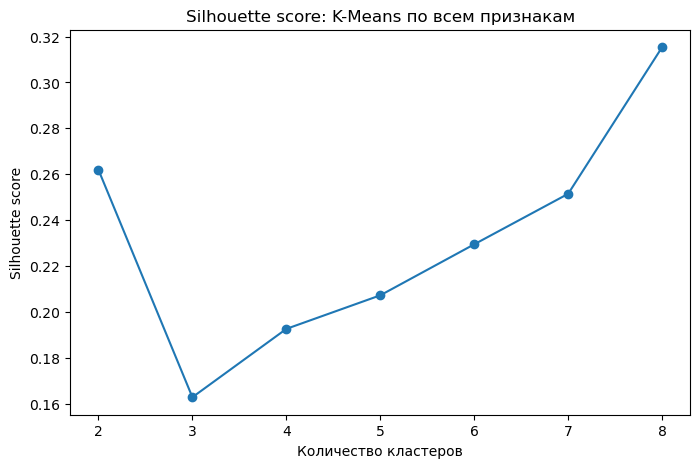

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 9),
    all_kmeans_scores,
    marker="o"
)

plt.title("Silhouette score: K-Means по всем признакам")
plt.xlabel("Количество кластеров")
plt.ylabel("Silhouette score")

plt.show()

In [24]:
best_k_all = range(2, 9)[np.argmax(all_kmeans_scores)]
best_score_all = max(all_kmeans_scores)

print("Лучший k по всем признакам:", best_k_all)
print("Лучший silhouette_score:", round(best_score_all, 4))

print(
    "Silhouette числовой модели при k=3:",
    round(kmeans_scores[1], 4)
)

Лучший k по всем признакам: 8
Лучший silhouette_score: 0.3153
Silhouette числовой модели при k=3: 0.464


### Вывод по модели со всеми признаками

После добавления категориальных признаков и применения One-Hot Encoding качество кластеризации снизилось.

Лучший результат модели по всем признакам получен при `k = 8`:

`silhouette_score = 0.3153`.

Для сравнения, числовая модель K-Means при `k = 3` показывает:

`silhouette_score = 0.4640`.

После One-Hot Encoding количество признаков увеличилось с 4 до 28.

Таким образом, в данном датасете K-Means лучше работает на числовых характеристиках.

Возможная причина заключается в том, что K-Means использует евклидово расстояние, а большое количество бинарных признаков после One-Hot Encoding изменяет структуру расстояний между объектами и может ухудшать разделение кластеров.

Для дальнейшей интерпретации используем модель K-Means, построенную на числовых признаках.

## 21. Визуализация характеристик кластеров

Для интерпретации выбранной модели визуализируем различия между тремя клиентскими сегментами по основным характеристикам.

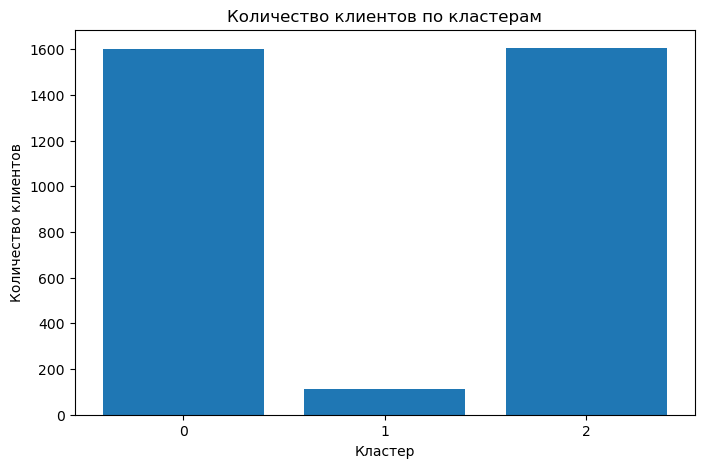

In [25]:
cluster_counts = (
    df_model["cluster"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))

plt.bar(
    cluster_counts.index.astype(str),
    cluster_counts.values
)

plt.title("Количество клиентов по кластерам")
plt.xlabel("Кластер")
plt.ylabel("Количество клиентов")

plt.show()

### Вывод

Наиболее крупными являются кластеры 0 и 2:

- кластер 0 - 1599 клиентов;
- кластер 2 - 1605 клиентов.

Кластер 1 заметно меньше и содержит только 111 клиентов.

Таким образом, основная часть клиентской базы распределена между двумя крупными сегментами, а отдельную небольшую группу составляют клиенты с существенно отличающимися характеристиками полисов.

## 22. Сравнение средних характеристик кластеров

Сравним средние значения основных числовых характеристик:

- длительность полиса;
- стоимость полиса;
- страховую сумму.

Эти признаки сильнее всего различают полученные клиентские сегменты.

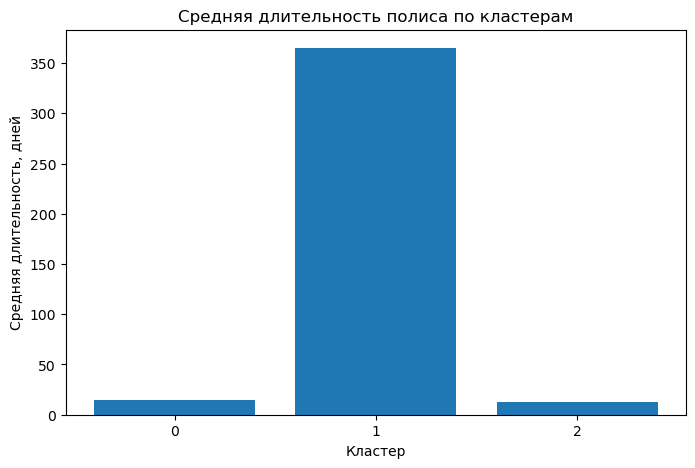

In [26]:
duration_by_cluster = (
    df_model.groupby("cluster")["duration"]
    .mean()
)

plt.figure(figsize=(8, 5))

plt.bar(
    duration_by_cluster.index.astype(str),
    duration_by_cluster.values
)

plt.title("Средняя длительность полиса по кластерам")
plt.xlabel("Кластер")
plt.ylabel("Средняя длительность, дней")

plt.show()

### Вывод

Кластеры 0 и 2 характеризуются сравнительно короткими полисами:

- кластер 0 - около 15 дней;
- кластер 2 - около 13 дней.

Кластер 1 резко отличается от остальных: средняя длительность полиса составляет 365 дней.

Таким образом, кластер 1 представляет отдельную группу клиентов с долгосрочными страховыми договорами.

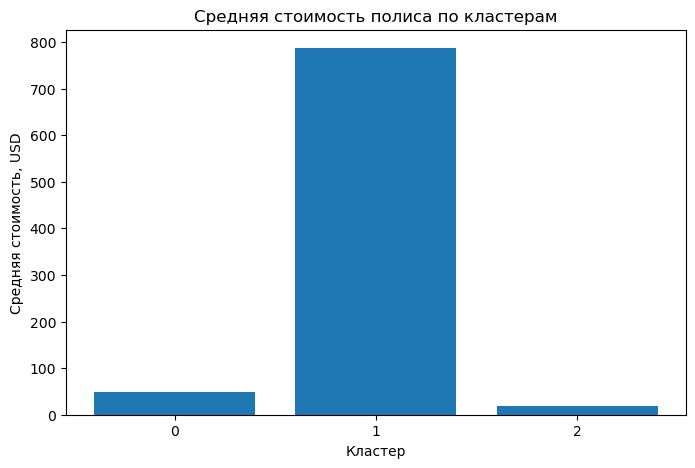

In [27]:
price_by_cluster = (
    df_model.groupby("cluster")["price_usd"]
    .mean()
)

plt.figure(figsize=(8, 5))

plt.bar(
    price_by_cluster.index.astype(str),
    price_by_cluster.values
)

plt.title("Средняя стоимость полиса по кластерам")
plt.xlabel("Кластер")
plt.ylabel("Средняя стоимость, USD")

plt.show()

### Вывод

Стоимость полисов существенно различается между сегментами.

- кластер 2 - самый бюджетный сегмент, средняя стоимость около 19.5 USD;
- кластер 0 - средняя стоимость около 48 USD;
- кластер 1 - наиболее дорогой сегмент, средняя стоимость около 787 USD.

Высокая стоимость полисов в кластере 1 дополнительно подтверждает, что это отдельная группа клиентов с долгосрочными и более дорогими страховыми продуктами.

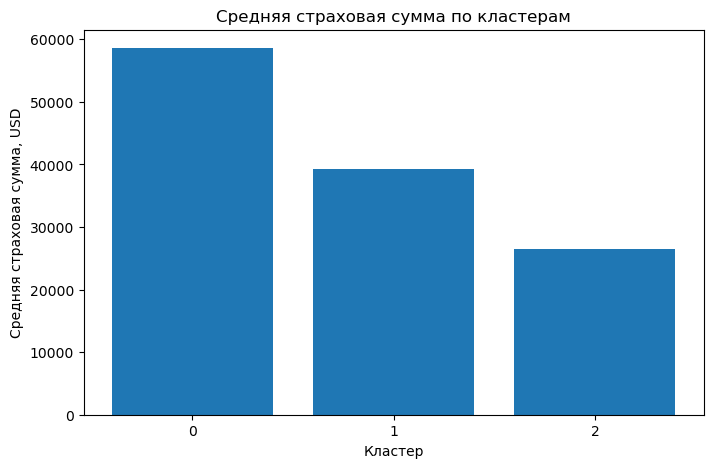

In [28]:
insurance_by_cluster = (
    df_model.groupby("cluster")["insurance_amount_usd"]
    .mean()
)

plt.figure(figsize=(8, 5))

plt.bar(
    insurance_by_cluster.index.astype(str),
    insurance_by_cluster.values
)

plt.title("Средняя страховая сумма по кластерам")
plt.xlabel("Кластер")
plt.ylabel("Средняя страховая сумма, USD")

plt.show()

### Вывод

Наибольшая средняя страховая сумма наблюдается в кластере 0 - около 58.6 тыс. USD.

В кластере 1 средняя страховая сумма составляет около 39.3 тыс. USD.

Кластер 2 характеризуется наиболее низкой страховой суммой - около 26.4 тыс. USD.

Таким образом, кластер 0 сочетает сравнительно короткие полисы с высоким уровнем страхового покрытия, а кластер 2 представляет более бюджетный сегмент.

## 23. Частота страховых выплат по кластерам

Сравним долю клиентов со страховыми выплатами в каждом кластере.

Показатель `claim_rate` показывает, какая доля клиентов в каждом сегменте имела страховой случай с выплатой.

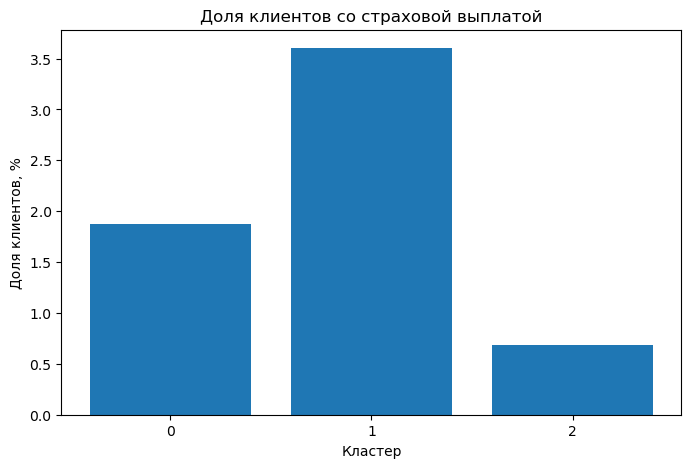

In [29]:
claim_rate_by_cluster = (
    df_model.groupby("cluster")["has_loss"]
    .mean()
    * 100
)

plt.figure(figsize=(8, 5))

plt.bar(
    claim_rate_by_cluster.index.astype(str),
    claim_rate_by_cluster.values
)

plt.title("Доля клиентов со страховой выплатой")
plt.xlabel("Кластер")
plt.ylabel("Доля клиентов, %")

plt.show()

### Вывод

Частота страховых выплат различается между сегментами:

- кластер 0 - около 1.88%;
- кластер 1 - около 3.60%;
- кластер 2 - около 0.69%.

Самая высокая доля клиентов со страховыми выплатами наблюдается в кластере 1 - группе с наиболее длительными и дорогими полисами.

Самая низкая частота выплат наблюдается в кластере 2.

При этом абсолютное количество страховых случаев остаётся небольшим, особенно в кластере 1, поэтому эти различия следует интерпретировать осторожно.

## 24. Бизнес-интерпретация клиентских сегментов

По результатам кластеризации можно выделить три основных клиентских сегмента.

### Кластер 0 - клиенты с высоким страховым покрытием

Характеристики:

- около 1599 клиентов;
- средняя длительность полиса - около 15 дней;
- средняя стоимость - около 48 USD;
- самая высокая средняя страховая сумма - около 58.6 тыс. USD;
- частота страховых выплат - около 1.88%.

Для этого сегмента можно рассматривать предложения с расширенным страховым покрытием, дополнительными опциями и пакетами с более высокой страховой суммой.

### Кластер 1 - долгосрочные и дорогие полисы

Характеристики:

- небольшой сегмент - около 111 клиентов;
- длительность полиса - 365 дней;
- самая высокая средняя стоимость - около 787 USD;
- средняя страховая сумма - около 39.3 тыс. USD;
- самая высокая частота страховых выплат - около 3.60%.

Этот сегмент заметно отличается от остальных и может требовать отдельной продуктовой и риск-стратегии.

Для таких клиентов могут быть актуальны долгосрочные программы страхования, персонализированные предложения и отдельный контроль страховых рисков.

### Кластер 2 - массовый бюджетный сегмент

Характеристики:

- около 1605 клиентов;
- короткие полисы - около 13 дней;
- самая низкая средняя стоимость - около 19.5 USD;
- самая низкая страховая сумма - около 26.4 тыс. USD;
- самая низкая частота выплат - около 0.69%.

Это наиболее массовый и бюджетный сегмент.

Для него могут быть эффективны массовые маркетинговые кампании, стандартные пакетные предложения и механики повторных продаж.

## 25. Итоговый вывод

В рамках практической работы была выполнена сегментация клиентов страховой компании на основе характеристик действующих страховых полисов.

В ходе анализа:

- использована очищенная витрина из предыдущего модуля;
- для кластеризации использованы все действующие полисы;
- признак `anomaly` не использовался как входной признак модели;
- числовые признаки были стандартизированы с помощью `StandardScaler`;
- выполнена иерархическая кластеризация;
- построена дендрограмма;
- оптимальное количество кластеров оценивалось с помощью `silhouette_score`;
- для K-Means дополнительно использован метод локтя;
- выполнено сравнение иерархической кластеризации и K-Means;
- отдельно проведена кластеризация только по числовым признакам и по всем признакам после One-Hot Encoding;
- модель на числовых признаках показала более высокое качество кластеризации;
- по метрике silhouette наиболее сильное разделение наблюдается при `k = 2`;
- для бизнес-интерпретации была выбрана модель K-Means с тремя кластерами, так как она позволяет выделить отдельный небольшой сегмент долгосрочных и дорогих полисов;
- для каждого сегмента построен профиль по длительности, стоимости полиса, страховой сумме и частоте страховых выплат.

В результате были выделены три основных клиентских сегмента:

**Кластер 0** - клиенты со сравнительно короткими полисами, средней стоимостью и высоким страховым покрытием.

**Кластер 1** - небольшая группа клиентов с долгосрочными, наиболее дорогими полисами и более высокой частотой страховых выплат.

**Кластер 2** - массовый бюджетный сегмент с короткими, недорогими полисами, более низкой страховой суммой и минимальной частотой выплат.

Полученная сегментация может использоваться для настройки различных маркетинговых предложений, продуктовых пакетов и более детального анализа страхового риска по отдельным группам клиентов.

При этом результаты по частоте страховых выплат следует интерпретировать осторожно, так как абсолютное количество страховых случаев невелико.